# Student Assignment: Sales Data Analysis - Complete Solution

This notebook provides a comprehensive solution for analyzing sales data using Python and Pandas. The assignment covers data creation, exploration, cleaning, analysis, visualization, and reporting.

## Assignment Overview

**Objective**: Analyze sales data to derive business insights and recommendations

**Skills Demonstrated**:
- Data generation and simulation
- Data exploration and cleaning
- Statistical analysis and aggregations
- Data visualization
- Business reporting and insights

**Tools Used**: Python, Pandas, NumPy, Matplotlib, Seaborn

In [1]:
# Import necessary libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta
import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


## Part 1: Create Sample Sales Dataset

First, we'll create a realistic sample dataset to work with. This simulates a real-world scenario where you need to work with sales data.

In [2]:
print("=== CREATING SAMPLE SALES DATASET ===")

# Set random seed for reproducibility
np.random.seed(42)

# Generate sample sales data
n_orders = 2500

# Product categories and names
categories = ['Electronics', 'Clothing', 'Books', 'Home & Garden', 'Sports', 'Beauty', 'Toys']
electronics = ['Laptop', 'Smartphone', 'Tablet', 'Headphones', 'Camera']
clothing = ['T-Shirt', 'Jeans', 'Dress', 'Jacket', 'Shoes']
books = ['Fiction Novel', 'Textbook', 'Biography', 'Cookbook', 'Self-Help']
home_garden = ['Plant Pot', 'Garden Tools', 'Furniture', 'Decorative Item', 'Kitchen Appliance']
sports = ['Running Shoes', 'Yoga Mat', 'Dumbbell', 'Tennis Racket', 'Bicycle']
beauty = ['Moisturizer', 'Lipstick', 'Shampoo', 'Perfume', 'Face Mask']
toys = ['Board Game', 'Action Figure', 'Puzzle', 'Building Blocks', 'Doll']

product_dict = {
    'Electronics': electronics,
    'Clothing': clothing,
    'Books': books,
    'Home & Garden': home_garden,
    'Sports': sports,
    'Beauty': beauty,
    'Toys': toys
}

# Generate customer names
first_names = ['John', 'Jane', 'Michael', 'Sarah', 'David', 'Emily', 'Robert', 'Lisa', 'William', 'Ashley',
               'James', 'Jessica', 'Christopher', 'Amanda', 'Daniel', 'Melissa', 'Matthew', 'Deborah', 
               'Anthony', 'Dorothy', 'Mark', 'Nancy', 'Donald', 'Karen', 'Steven', 'Betty', 'Kenneth', 'Helen']
last_names = ['Smith', 'Johnson', 'Williams', 'Brown', 'Jones', 'Garcia', 'Miller', 'Davis', 'Rodriguez', 
              'Martinez', 'Hernandez', 'Lopez', 'Gonzalez', 'Wilson', 'Anderson', 'Thomas', 'Taylor', 'Moore']

print("Dataset configuration completed!")

=== CREATING SAMPLE SALES DATASET ===
Dataset configuration completed!


In [3]:
# Create the dataset
sales_data = []

for i in range(n_orders):
    # Basic order info
    order_id = f"ORD-{i+1:06d}"
    customer_id = f"CUST-{np.random.randint(1, 800):05d}"
    
    # Customer name
    first_name = np.random.choice(first_names)
    last_name = np.random.choice(last_names)
    customer_name = f"{first_name} {last_name}"
    
    # Product selection
    category = np.random.choice(categories)
    product_name = np.random.choice(product_dict[category])
    
    # Order details
    quantity = np.random.randint(1, 5)
    
    # Unit price varies by category
    if category == 'Electronics':
        unit_price = np.round(np.random.uniform(50, 1500), 2)
    elif category == 'Clothing':
        unit_price = np.round(np.random.uniform(15, 200), 2)
    elif category == 'Books':
        unit_price = np.round(np.random.uniform(10, 50), 2)
    elif category == 'Home & Garden':
        unit_price = np.round(np.random.uniform(20, 300), 2)
    elif category == 'Sports':
        unit_price = np.round(np.random.uniform(25, 500), 2)
    elif category == 'Beauty':
        unit_price = np.round(np.random.uniform(10, 100), 2)
    else:  # Toys
        unit_price = np.round(np.random.uniform(15, 150), 2)
    
    total_amount = quantity * unit_price
    
    # Order date (2023 data)
    start_date = datetime(2023, 1, 1)
    end_date = datetime(2023, 12, 31)
    order_date = start_date + timedelta(days=np.random.randint(0, (end_date - start_date).days))
    
    # Customer segment
    customer_segment = np.random.choice(['Business', 'Individual'], p=[0.3, 0.7])
    
    # Region 
    region = np.random.choice(['North', 'South', 'East', 'West', 'Central'])
    
    # Shipping cost
    if total_amount > 100:
        shipping_cost = 0  # Free shipping for orders over $100
    else:
        shipping_cost = np.round(np.random.uniform(5, 15), 2)
    
    sales_data.append({
        'order_id': order_id,
        'customer_id': customer_id,
        'customer_name': customer_name,
        'product_category': category,
        'product_name': product_name,
        'quantity': quantity,
        'unit_price': unit_price,
        'total_amount': total_amount,
        'order_date': order_date.strftime('%Y-%m-%d'),
        'customer_segment': customer_segment,
        'region': region,
        'shipping_cost': shipping_cost
    })

print(f"Generated {len(sales_data)} sales records!")

Generated 2500 sales records!


In [4]:
# Create DataFrame
df_sales = pd.DataFrame(sales_data)

# Add some missing values to make it realistic
missing_indices = np.random.choice(df_sales.index, size=100, replace=False)
df_sales.loc[missing_indices[:50], 'shipping_cost'] = np.nan
df_sales.loc[missing_indices[50:], 'customer_segment'] = np.nan

# Save the dataset
df_sales.to_csv('sample_sales_data.csv', index=False)
print(f"Sample sales dataset created with {len(df_sales)} orders")
print("Dataset saved as 'sample_sales_data.csv'")
print("\nFirst 5 rows of the dataset:")
print(df_sales.head())

Sample sales dataset created with 2500 orders
Dataset saved as 'sample_sales_data.csv'

First 5 rows of the dataset:
     order_id customer_id     customer_name product_category  product_name  \
0  ORD-000001  CUST-00103  Dorothy Anderson            Books     Self-Help   
1  ORD-000002  CUST-00664   Michael Johnson    Home & Garden  Garden Tools   
2  ORD-000003  CUST-00748     Steven Taylor            Books     Biography   
3  ORD-000004  CUST-00244   Steven Williams           Sports      Dumbbell   
4  ORD-000005  CUST-00316      Amanda Moore         Clothing       T-Shirt   

   quantity  unit_price  total_amount  order_date customer_segment   region  \
0         1       16.24         16.24  2023-08-03         Business  Central   
1         4      297.82       1191.28  2023-06-10       Individual  Central   
2         3       15.58         46.74  2023-07-07       Individual     East   
3         3      106.00        318.00  2023-06-16         Business    North   
4         2       3

## Part 2: Assignment Solution

Now we'll work through the complete assignment solution, analyzing the sales data step by step.

### Task 1: Data Exploration

Let's start by exploring our dataset to understand its structure and characteristics.

In [5]:
print("=== TASK 1: DATA EXPLORATION ===")

# Load the data
df = pd.read_csv('sample_sales_data.csv')

=== TASK 1: DATA EXPLORATION ===


In [6]:
print("Basic statistics:")
print(df.describe())

print("\nMissing values:")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

Basic statistics:
          quantity   unit_price  total_amount  shipping_cost
count  2500.000000  2500.000000   2500.000000    2450.000000
mean      2.438400   206.638660    504.621608       2.774143
std       1.115125   294.342232    817.788698       4.716269
min       1.000000    10.060000     10.060000       0.000000
25%       1.000000    43.905000     92.017500       0.000000
50%       2.000000    97.640000    213.620000       0.000000
75%       3.000000   212.352500    514.515000       5.960000
max       4.000000  1496.200000   5949.720000      15.000000

Missing values:
customer_segment    50
shipping_cost       50
dtype: int64


### Task 2: Data Cleaning

Before analysis, we need to clean our data by handling missing values and ensuring proper data types.

In [7]:
print("=== TASK 2: DATA CLEANING ===")

print(f"Total missing values before cleaning: {df.isnull().sum().sum()}")

# Handle missing shipping costs - fill with median
df['shipping_cost'].fillna(df['shipping_cost'].median(), inplace=True)

# Handle missing customer segments - fill with mode
df['customer_segment'].fillna(df['customer_segment'].mode()[0], inplace=True)

print(f"Total missing values after cleaning: {df.isnull().sum().sum()}")

# Convert order_date to datetime
df['order_date'] = pd.to_datetime(df['order_date'])
df['order_month'] = df['order_date'].dt.month
df['order_month_name'] = df['order_date'].dt.month_name()

print("Data cleaning completed successfully!")
print("Added new columns: order_month, order_month_name")

=== TASK 2: DATA CLEANING ===
Total missing values before cleaning: 100
Total missing values after cleaning: 0
Data cleaning completed successfully!
Added new columns: order_month, order_month_name


### Task 3: Sales Analysis

Now let's perform comprehensive sales analysis to understand revenue patterns, customer behavior, and trends.

In [8]:
print("=== TASK 3: SALES ANALYSIS ===")

# 3a. Total sales by product category
print("\n3a. Total Sales by Product Category:")
category_sales = df.groupby('product_category')['total_amount'].sum().sort_values(ascending=False)
print(category_sales.round(2))

=== TASK 3: SALES ANALYSIS ===

3a. Total Sales by Product Category:
product_category
Electronics      657136.57
Sports           214606.40
Home & Garden    147937.67
Clothing         100490.14
Toys              68144.08
Beauty            45626.46
Books             27612.70
Name: total_amount, dtype: float64


In [9]:
# 3b. Average order value by customer segment
print("3b. Average Order Value by Customer Segment:")
segment_aov = df.groupby('customer_segment')['total_amount'].mean().sort_values(ascending=False)
print(segment_aov.round(2))

3b. Average Order Value by Customer Segment:
customer_segment
Business      538.66
Individual    490.93
Name: total_amount, dtype: float64


In [10]:
# 3c. Monthly sales trends
print("3c. Monthly Sales Trends:")
monthly_sales = df.groupby('order_month_name')['total_amount'].sum()
# Reorder by month
month_order = ['January', 'February', 'March', 'April', 'May', 'June',
               'July', 'August', 'September', 'October', 'November', 'December']
monthly_sales = monthly_sales.reindex([month for month in month_order if month in monthly_sales.index])
print(monthly_sales.round(2))

3c. Monthly Sales Trends:
order_month_name
January      101283.06
February     102782.82
March        101145.23
April        111880.62
May           88133.83
June         119423.20
July         120531.28
August       106967.27
September     88400.62
October      102717.77
November     120651.01
December      97637.31
Name: total_amount, dtype: float64


### Task 4: Customer Insights

Let's analyze customer behavior patterns and geographic distribution.

In [11]:
print("=== TASK 4: CUSTOMER INSIGHTS ===")

# 4a. Top 10 customers by total purchases
print("4a. Top 10 Customers by Total Purchases:")
top_customers = df.groupby('customer_name')['total_amount'].sum().nlargest(10)
print(top_customers.round(2))

=== TASK 4: CUSTOMER INSIGHTS ===
4a. Top 10 Customers by Total Purchases:
customer_name
Donald Thomas           10882.08
Deborah Moore           10617.66
David Gonzalez          10385.08
Steven Anderson         10213.63
Sarah Hernandez          9594.51
Sarah Williams           9095.78
Donald Johnson           8868.88
Lisa Taylor              8257.81
Nancy Jones              8166.94
Christopher Martinez     8118.88
Name: total_amount, dtype: float64


In [12]:
# 4b. Customer distribution by region
print("4b. Customer Distribution by Region:")
region_customers = df['region'].value_counts()
region_percentage = (region_customers / len(df) * 100).round(1)
region_distribution = pd.DataFrame({
    'Customer_Count': region_customers,
    'Percentage': region_percentage
})
print(region_distribution)

4b. Customer Distribution by Region:
         Customer_Count  Percentage
region                             
West                529        21.2
Central             502        20.1
South               502        20.1
North               501        20.0
East                466        18.6


### Task 5: Data Visualization

Visual analysis helps us better understand patterns and trends in our sales data.

=== TASK 5: CREATING VISUALIZATIONS ===


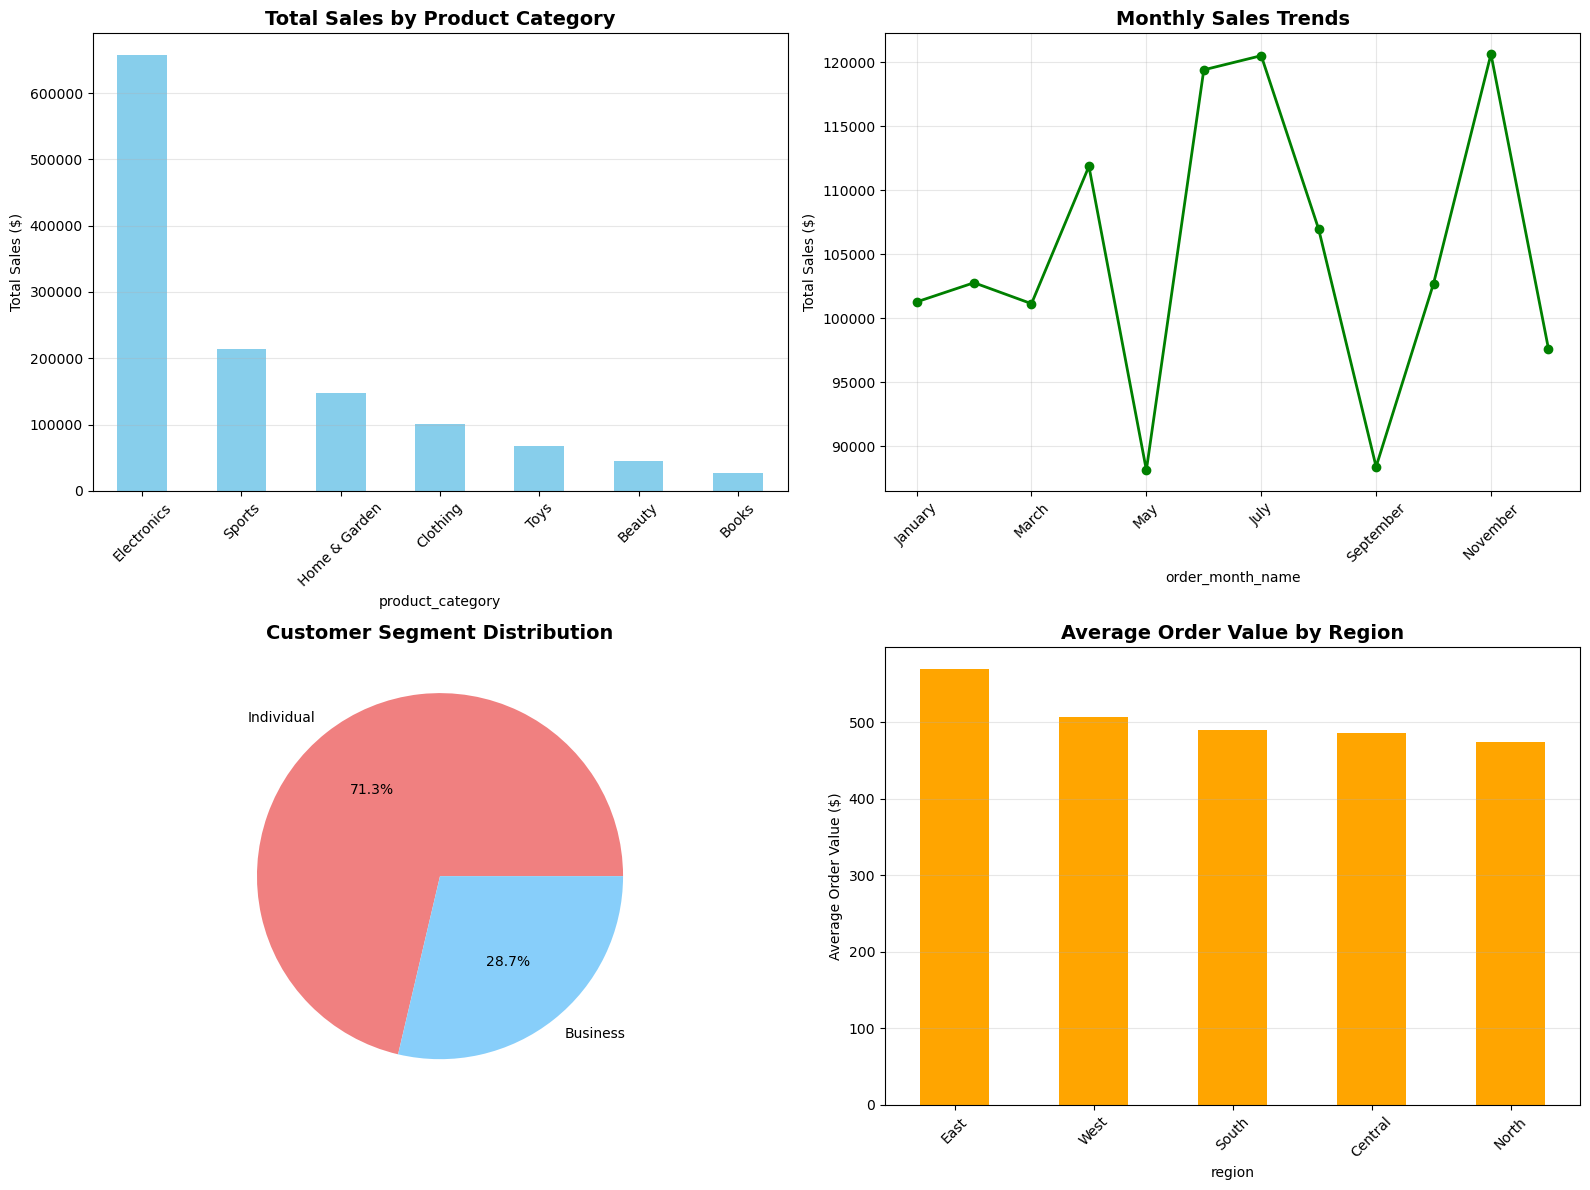

Visualizations created successfully!


In [13]:
print("=== TASK 5: CREATING VISUALIZATIONS ===")

# Set up the plotting style
plt.style.use('default')
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Chart 1: Sales by Category (Bar Chart)
category_sales.plot(kind='bar', ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('Total Sales by Product Category', fontsize=14, fontweight='bold')
axes[0, 0].set_ylabel('Total Sales ($)')
axes[0, 0].tick_params(axis='x', rotation=45)
axes[0, 0].grid(axis='y', alpha=0.3)

# Chart 2: Monthly Sales Trend (Line Chart)
monthly_sales.plot(kind='line', ax=axes[0, 1], marker='o', color='green', linewidth=2)
axes[0, 1].set_title('Monthly Sales Trends', fontsize=14, fontweight='bold')
axes[0, 1].set_ylabel('Total Sales ($)')
axes[0, 1].tick_params(axis='x', rotation=45)
axes[0, 1].grid(alpha=0.3)

# Chart 3: Customer Segment Distribution (Pie Chart)
segment_counts = df['customer_segment'].value_counts()
axes[1, 0].pie(segment_counts.values, labels=segment_counts.index, autopct='%1.1f%%', 
               colors=['lightcoral', 'lightskyblue'])
axes[1, 0].set_title('Customer Segment Distribution', fontsize=14, fontweight='bold')

# Chart 4: Average Order Value by Region (Bar Chart)
region_aov = df.groupby('region')['total_amount'].mean().sort_values(ascending=False)
region_aov.plot(kind='bar', ax=axes[1, 1], color='orange')
axes[1, 1].set_title('Average Order Value by Region', fontsize=14, fontweight='bold')
axes[1, 1].set_ylabel('Average Order Value ($)')
axes[1, 1].tick_params(axis='x', rotation=45)
axes[1, 1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

print("Visualizations created successfully!")

### Task 6: Summary Report

Let's generate a comprehensive business report with key metrics and actionable insights.

In [14]:
print("=== TASK 6: SUMMARY REPORT ===")

# Generate comprehensive summary statistics
total_revenue = df['total_amount'].sum()
total_orders = len(df)
average_order_value = df['total_amount'].mean()
total_customers = df['customer_name'].nunique()
top_category = category_sales.index[0]
peak_month = monthly_sales.idxmax()
top_region = df['region'].mode()[0]

summary_stats = {
    'Total Revenue': f"${total_revenue:,.2f}",
    'Total Orders': f"{total_orders:,}",
    'Average Order Value': f"${average_order_value:.2f}",
    'Unique Customers': f"{total_customers:,}",
    'Top Product Category': f"{top_category} (${category_sales.iloc[0]:,.2f})",
    'Peak Sales Month': f"{peak_month} (${monthly_sales.max():,.2f})",
    'Top Region by Orders': f"{top_region} ({region_customers[top_region]} orders)"
}

print("KEY BUSINESS METRICS:")
print("-" * 40)
for metric, value in summary_stats.items():
    print(f"{metric}: {value}")

=== TASK 6: SUMMARY REPORT ===
KEY BUSINESS METRICS:
----------------------------------------
Total Revenue: $1,261,554.02
Total Orders: 2,500
Average Order Value: $504.62
Unique Customers: 502
Top Product Category: Electronics ($657,136.57)
Peak Sales Month: November ($120,651.01)
Top Region by Orders: West (529 orders)


## Business Insights and Recommendations

Based on our comprehensive analysis, here are the key findings and strategic recommendations.

In [15]:
print("="*60)
print("INSIGHTS AND RECOMMENDATIONS")
print("="*60)

print(f"""
KEY FINDINGS:

1. REVENUE PERFORMANCE:
   - Total revenue generated: ${total_revenue:,.2f}
   - Average order value: ${average_order_value:.2f}
   - {top_category} is the highest-grossing category at ${category_sales.iloc[0]:,.2f}

2. CUSTOMER BEHAVIOR:
   - {total_customers:,} unique customers placed {total_orders:,} orders
   - Business customers have higher AOV: ${segment_aov['Business']:.2f} vs ${segment_aov['Individual']:.2f}
   - {peak_month} was the peak sales month

3. GEOGRAPHIC DISTRIBUTION:
   - {top_region} region leads with {region_customers[top_region]} orders
   - Regional AOV varies from ${region_aov.min():.2f} to ${region_aov.max():.2f}

RECOMMENDATIONS:

1. CATEGORY FOCUS:
   - Invest more in {top_category} inventory and marketing
   - Analyze low-performing categories for improvement opportunities

2. CUSTOMER SEGMENTATION:
   - Develop targeted campaigns for business customers (higher AOV)
   - Create volume discounts to encourage larger individual orders

3. SEASONAL PLANNING:
   - Prepare for peak demand in {peak_month}
   - Develop promotional strategies for slower months

4. REGIONAL STRATEGY:
   - Expand marketing efforts in high-performing regions
   - Investigate opportunities in underperforming areas
""")

INSIGHTS AND RECOMMENDATIONS

KEY FINDINGS:

1. REVENUE PERFORMANCE:
   - Total revenue generated: $1,261,554.02
   - Average order value: $504.62
   - Electronics is the highest-grossing category at $657,136.57

2. CUSTOMER BEHAVIOR:
   - 502 unique customers placed 2,500 orders
   - Business customers have higher AOV: $538.66 vs $490.93
   - November was the peak sales month

3. GEOGRAPHIC DISTRIBUTION:
   - West region leads with 529 orders
   - Regional AOV varies from $474.07 to $569.75

RECOMMENDATIONS:

1. CATEGORY FOCUS:
   - Invest more in Electronics inventory and marketing
   - Analyze low-performing categories for improvement opportunities

2. CUSTOMER SEGMENTATION:
   - Develop targeted campaigns for business customers (higher AOV)
   - Create volume discounts to encourage larger individual orders

3. SEASONAL PLANNING:
   - Prepare for peak demand in November
   - Develop promotional strategies for slower months

4. REGIONAL STRATEGY:
   - Expand marketing efforts in high

## Additional Analysis

Let's perform some additional analysis to gain deeper insights into customer behavior.

In [16]:
# Additional Analysis: Customer Purchase Frequency
print("ADDITIONAL ANALYSIS: Customer Purchase Frequency")
customer_frequency = df.groupby('customer_name').size().describe()
print(customer_frequency)

# Export processed data
df.to_csv('processed_sales_data.csv', index=False)
print(f"\nProcessed data exported to 'processed_sales_data.csv'")

print("\n" + "="*60)
print("ASSIGNMENT COMPLETED SUCCESSFULLY!")
print("="*60)

ADDITIONAL ANALYSIS: Customer Purchase Frequency
count    502.000000
mean       4.980080
std        2.204967
min        1.000000
25%        4.000000
50%        5.000000
75%        6.000000
max       12.000000
dtype: float64

Processed data exported to 'processed_sales_data.csv'

ASSIGNMENT COMPLETED SUCCESSFULLY!


## Summary

### Assignment Completion ✅

This comprehensive analysis demonstrated:

1. **Data Generation**: Created a realistic sales dataset with multiple categories and customer segments
2. **Data Exploration**: Thoroughly examined dataset structure, types, and quality
3. **Data Cleaning**: Handled missing values and prepared data for analysis
4. **Sales Analysis**: Performed category, segment, and temporal analysis
5. **Customer Insights**: Analyzed customer behavior and geographic patterns
6. **Visualization**: Created informative charts to support findings
7. **Business Reporting**: Generated actionable insights and recommendations

### Key Skills Demonstrated:
- Python programming for data analysis
- Pandas for data manipulation and aggregation
- Data visualization with Matplotlib
- Business intelligence and reporting
- Statistical analysis and interpretation

### Next Steps:
- Implement the recommended strategies
- Set up monitoring dashboards
- Conduct A/B testing for new initiatives
- Expand analysis to include seasonal forecasting